In [ ]:
!pip install gdown python-dateutil pandas matplotlib seaborn plotly
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import numpy as np

CARGA DE DATOS

In [ ]:
df_csv = pd.read_csv("/content/ventas_bodega_csv_200.csv", delimiter=';')
df_csv

,id_venta,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,ciudad,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio,origen_archivo
0,CSV-0001,4/3/2026,Cabernet Clásico,Tinto,Cabernet Sauvignon,8,5200,0.0,41600.0,Vinoteca,Mendoza,Luján de Cuyo,Efectivo,Lucía Pérez,Entregado,5.0,0,CSV
1,CSV-0002,1/3/2026,malbec reserva,Tinto,Malbec,17,4200,0.2,58620.0,Salón de ventas,Mendoza,Ciudad de Mendoza,Efectivo,Camila Torres,Entregado,5.0,1500,CSV
2,CSV-0003,19/4/2026,Sauvignon Blanc,Blanco,Sauvignon Blanc,11,7500,0.05,78375.0,Tienda Online,Mendoza,Ciudad de Mendoza,Efectivo,Lucía Pérez,Entregado,NaN,0,CSV
3,CSV-0004,9/3/2026,Rosé de Malbec,Rosado,Malbec,2,12000,20%,19200.0,Vinoteca,Buenos Aires,Mar del Plata,Transferencia,Camila Torres,Entregado,4.0,0,CSV
4,CSV-0005,18/1/2026,Rosé de Malbec,Rosado,Malbec,2,6100,0.1,10980.0,Restaurante,San Juan,NaN,Transferencia,Tomás Molina,Devuelto,2.0,0,CSV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,CSV-0196,13/2/2026,Blend Gran Corte,Tinto,Blend,5,12000,0.05,59000.0,Tienda Online,Neuquén,San Martín de los Andes,Mercado Pago,Lucía Pérez,Cancelado,NaN,2000,CSV
196,CSV-0197,2/1/2026,Cabernet Clásico,Tinto,Cabernet Sauvignon,14,5200,0.05,69160.0,Salón de ventas,Neuquén,Neuquén Capital,Mercado Pago,Tomás Molina,Entregado,2.0,0,CSV
197,CSV-0198,5/5/2026,Rosé de Malbec,Rosado,Malbec,1,4200,20%,3360.0,Vinoteca,Mendoza,Maipú,Transferencia,Camila Torres,Entregado,1.0,0,CSV
198,CSV-0199,15/2/2026,Sauvignon Blanc,Blanco,Sauvignon Blanc,4,4800,0.2,17360.0,Vinoteca,Mendoza,Maipú,Transferencia,Sofía Herrera,Entregado,2.0,2000,CSV


In [ ]:
df_json = pd.read_json("/content/ventas_bodega_json_200.json")
df_json

,id_venta,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,ciudad,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio,origen_archivo
0,JSON-0001,2026-05-22T00:00:00,Espumante Brut,Espumante,Blend,16,4200,0.00,68700.0,Restaurante,Santa Fe,Santa Fe Capital,Transferencia,Camila Torres,Entregado,1.0,1500.0,JSON
1,JSON-0002,2026-02-28T00:00:00,Cabernet Clásico,Tinto,Cabernet Sauvignon,7,12000,0.10,78100.0,Distribuidor,San Juan,San Juan Capital,Mercado Pago,Camila Torres,Entregado,1.0,2500.0,JSON
2,JSON-0003,2026-01-05,Malbec Reserva,Tinto,Malbec,7,5200,0.15,32140.0,Salón de ventas,Córdoba,Villa Carlos Paz,Mercado Pago,Martín Gómez,Cancelado,NaN,1200.0,JSON
3,JSON-0004,2026-04-09T00:00:00,Espumante Brut,Espumante,Blend,24,5200,0.00,$124800.0,Tienda Online,Neuquén,San Martín de los Andes,Efectivo,Martín Gómez,Entregado,3.0,0.0,JSON
4,JSON-0005,2026-04-12T00:00:00,Cabernet Clásico,Tinto,Cabernet Sauvignon,11,4200,0.10,43080.0,Restaurante,Buenos Aires,Mar del Plata,Tarjeta débito,Sofía Herrera,Pendiente,NaN,1500.0,JSON
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,JSON-0196,2026-02-07,Espumante Brut,Espumante,Blend,24,5200,0.15,106880.0,Restaurante,Santa Fe,Rosario,Efectivo,Martín Gómez,Pendiente,NaN,800.0,JSON
196,JSON-0197,2026-03-06T00:00:00,Rosé de Malbec,Rosado,Malbec,18,4200,0.15,$64260.0,Salón de ventas,Santa Fe,Santa Fe Capital,Transferencia,Tomás Molina,Entregado,2.0,0.0,JSON
197,JSON-0198,2026-03-08,Cabernet Clásico,Tinto,Cabernet Sauvignon,12,8900,0.20,86640.0,Tienda Online,Santa Fe,Santa Fe Capital,Efectivo,Lucía Pérez,Entregado,3.0,1200.0,JSON
198,JSON-0199,2026-05-28T00:00:00,Rosé de Malbec,Rosado,Malbec,19,5200,0.10,$90420.0,Restaurante,Neuquén,Neuquén Capital,Tarjeta crédito,Tomás Molina,Entregado,5.0,NaN,JSON


UNIFICACION DE DATOS Y LIMPIEZA

In [ ]:
df= pd.concat([df_csv, df_json])
df
#unimos ambas fuentes de datos

,id_venta,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,ciudad,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio,origen_archivo
0,CSV-0001,4/3/2026,Cabernet Clásico,Tinto,Cabernet Sauvignon,8,5200,0.0,41600.0,Vinoteca,Mendoza,Luján de Cuyo,Efectivo,Lucía Pérez,Entregado,5.0,0.0,CSV
1,CSV-0002,1/3/2026,malbec reserva,Tinto,Malbec,17,4200,0.2,58620.0,Salón de ventas,Mendoza,Ciudad de Mendoza,Efectivo,Camila Torres,Entregado,5.0,1500.0,CSV
2,CSV-0003,19/4/2026,Sauvignon Blanc,Blanco,Sauvignon Blanc,11,7500,0.05,78375.0,Tienda Online,Mendoza,Ciudad de Mendoza,Efectivo,Lucía Pérez,Entregado,NaN,0.0,CSV
3,CSV-0004,9/3/2026,Rosé de Malbec,Rosado,Malbec,2,12000,20%,19200.0,Vinoteca,Buenos Aires,Mar del Plata,Transferencia,Camila Torres,Entregado,4.0,0.0,CSV
4,CSV-0005,18/1/2026,Rosé de Malbec,Rosado,Malbec,2,6100,0.1,10980.0,Restaurante,San Juan,NaN,Transferencia,Tomás Molina,Devuelto,2.0,0.0,CSV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,JSON-0196,2026-02-07,Espumante Brut,Espumante,Blend,24,5200,0.15,106880.0,Restaurante,Santa Fe,Rosario,Efectivo,Martín Gómez,Pendiente,NaN,800.0,JSON
196,JSON-0197,2026-03-06T00:00:00,Rosé de Malbec,Rosado,Malbec,18,4200,0.15,$64260.0,Salón de ventas,Santa Fe,Santa Fe Capital,Transferencia,Tomás Molina,Entregado,2.0,0.0,JSON
197,JSON-0198,2026-03-08,Cabernet Clásico,Tinto,Cabernet Sauvignon,12,8900,0.2,86640.0,Tienda Online,Santa Fe,Santa Fe Capital,Efectivo,Lucía Pérez,Entregado,3.0,1200.0,JSON
198,JSON-0199,2026-05-28T00:00:00,Rosé de Malbec,Rosado,Malbec,19,5200,0.1,$90420.0,Restaurante,Neuquén,Neuquén Capital,Tarjeta crédito,Tomás Molina,Entregado,5.0,NaN,JSON


In [ ]:
df = df.reset_index(drop=True)
df['ID'] = df.index
display(df[['id_venta', 'ID']].head())
#reemplazamos la columna id_venta por ID secuencial para todos los datos

,id_venta,ID
0,CSV-0001,0
1,CSV-0002,1
2,CSV-0003,2
3,CSV-0004,3
4,CSV-0005,4


In [ ]:
df = df.drop(columns=['id_venta'])
display(df.head())
#eliminamos columna id_venta

,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,ciudad,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio,origen_archivo,ID
0,4/3/2026,Cabernet Clásico,Tinto,Cabernet Sauvignon,8,5200,0.0,41600.0,Vinoteca,Mendoza,Luján de Cuyo,Efectivo,Lucía Pérez,Entregado,5.0,0.0,CSV,0
1,1/3/2026,malbec reserva,Tinto,Malbec,17,4200,0.2,58620.0,Salón de ventas,Mendoza,Ciudad de Mendoza,Efectivo,Camila Torres,Entregado,5.0,1500.0,CSV,1
2,19/4/2026,Sauvignon Blanc,Blanco,Sauvignon Blanc,11,7500,0.05,78375.0,Tienda Online,Mendoza,Ciudad de Mendoza,Efectivo,Lucía Pérez,Entregado,NaN,0.0,CSV,2
3,9/3/2026,Rosé de Malbec,Rosado,Malbec,2,12000,20%,19200.0,Vinoteca,Buenos Aires,Mar del Plata,Transferencia,Camila Torres,Entregado,4.0,0.0,CSV,3
4,18/1/2026,Rosé de Malbec,Rosado,Malbec,2,6100,0.1,10980.0,Restaurante,San Juan,NaN,Transferencia,Tomás Molina,Devuelto,2.0,0.0,CSV,4


In [ ]:
cols = df.columns.tolist()
cols.remove('ID')
df = df[['ID'] + cols]
display(df.head())
#la colocamos al principio del dataset

,ID,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,ciudad,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio,origen_archivo
0,0,4/3/2026,Cabernet Clásico,Tinto,Cabernet Sauvignon,8,5200,0.0,41600.0,Vinoteca,Mendoza,Luján de Cuyo,Efectivo,Lucía Pérez,Entregado,5.0,0.0,CSV
1,1,1/3/2026,malbec reserva,Tinto,Malbec,17,4200,0.2,58620.0,Salón de ventas,Mendoza,Ciudad de Mendoza,Efectivo,Camila Torres,Entregado,5.0,1500.0,CSV
2,2,19/4/2026,Sauvignon Blanc,Blanco,Sauvignon Blanc,11,7500,0.05,78375.0,Tienda Online,Mendoza,Ciudad de Mendoza,Efectivo,Lucía Pérez,Entregado,NaN,0.0,CSV
3,3,9/3/2026,Rosé de Malbec,Rosado,Malbec,2,12000,20%,19200.0,Vinoteca,Buenos Aires,Mar del Plata,Transferencia,Camila Torres,Entregado,4.0,0.0,CSV
4,4,18/1/2026,Rosé de Malbec,Rosado,Malbec,2,6100,0.1,10980.0,Restaurante,San Juan,NaN,Transferencia,Tomás Molina,Devuelto,2.0,0.0,CSV


In [ ]:
df = df.drop(columns=['origen_archivo'])
df
#eliminamos columna origen, no va a ser relevane para nuestro análisis

,ID,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,ciudad,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio
0,0,4/3/2026,Cabernet Clásico,Tinto,Cabernet Sauvignon,8,5200,0.0,41600.0,Vinoteca,Mendoza,Luján de Cuyo,Efectivo,Lucía Pérez,Entregado,5.0,0.0
1,1,1/3/2026,malbec reserva,Tinto,Malbec,17,4200,0.2,58620.0,Salón de ventas,Mendoza,Ciudad de Mendoza,Efectivo,Camila Torres,Entregado,5.0,1500.0
2,2,19/4/2026,Sauvignon Blanc,Blanco,Sauvignon Blanc,11,7500,0.05,78375.0,Tienda Online,Mendoza,Ciudad de Mendoza,Efectivo,Lucía Pérez,Entregado,NaN,0.0
3,3,9/3/2026,Rosé de Malbec,Rosado,Malbec,2,12000,20%,19200.0,Vinoteca,Buenos Aires,Mar del Plata,Transferencia,Camila Torres,Entregado,4.0,0.0
4,4,18/1/2026,Rosé de Malbec,Rosado,Malbec,2,6100,0.1,10980.0,Restaurante,San Juan,NaN,Transferencia,Tomás Molina,Devuelto,2.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395,2026-02-07,Espumante Brut,Espumante,Blend,24,5200,0.15,106880.0,Restaurante,Santa Fe,Rosario,Efectivo,Martín Gómez,Pendiente,NaN,800.0
396,396,2026-03-06T00:00:00,Rosé de Malbec,Rosado,Malbec,18,4200,0.15,$64260.0,Salón de ventas,Santa Fe,Santa Fe Capital,Transferencia,Tomás Molina,Entregado,2.0,0.0
397,397,2026-03-08,Cabernet Clásico,Tinto,Cabernet Sauvignon,12,8900,0.2,86640.0,Tienda Online,Santa Fe,Santa Fe Capital,Efectivo,Lucía Pérez,Entregado,3.0,1200.0
398,398,2026-05-28T00:00:00,Rosé de Malbec,Rosado,Malbec,19,5200,0.1,$90420.0,Restaurante,Neuquén,Neuquén Capital,Tarjeta crédito,Tomás Molina,Entregado,5.0,NaN


In [ ]:
df= df.drop(columns=['ciudad'])
#eliminamos columna ciudad, no va a ser relevante para nuestro análisis

CONVERSION DE DATOS Y VALORES NULOS

In [ ]:
def limpiar_porcentaje(valor):
    if pd.isna(valor):
        return valor

    if isinstance(valor, str):
        if '%' in valor:
            return float(valor.replace('%', '').strip()) / 100
        return float(valor)

    return float(valor)

df['descuento'] = df['descuento'].apply(limpiar_porcentaje)
display(df.head())
# con esta función habían datos en la columna de descuento con "%" lo cual lo limpiamos y pasamos toda la columna a tipo float

,ID,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio
0,0,4/3/2026,Cabernet Clásico,Tinto,Cabernet Sauvignon,8,5200,0.00,41600.0,Vinoteca,Mendoza,Efectivo,Lucía Pérez,Entregado,5.0,0.0
1,1,1/3/2026,malbec reserva,Tinto,Malbec,17,4200,0.20,58620.0,Salón de ventas,Mendoza,Efectivo,Camila Torres,Entregado,5.0,1500.0
2,2,19/4/2026,Sauvignon Blanc,Blanco,Sauvignon Blanc,11,7500,0.05,78375.0,Tienda Online,Mendoza,Efectivo,Lucía Pérez,Entregado,NaN,0.0
3,3,9/3/2026,Rosé de Malbec,Rosado,Malbec,2,12000,0.20,19200.0,Vinoteca,Buenos Aires,Transferencia,Camila Torres,Entregado,4.0,0.0
4,4,18/1/2026,Rosé de Malbec,Rosado,Malbec,2,6100,0.10,10980.0,Restaurante,San Juan,Transferencia,Tomás Molina,Devuelto,2.0,0.0


In [ ]:
df['total_venta'] = df['total_venta'].astype(str).str.replace("$", "", regex=False).astype(float)
df
#en esta columna habían datos de diferentes valores, algunos con "$" por lo que lo reemplazamos y los volvimos tipo float

,ID,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio
0,0,4/3/2026,Cabernet Clásico,Tinto,Cabernet Sauvignon,8,5200,0.00,41600.0,Vinoteca,Mendoza,Efectivo,Lucía Pérez,Entregado,5.0,0.0
1,1,1/3/2026,malbec reserva,Tinto,Malbec,17,4200,0.20,58620.0,Salón de ventas,Mendoza,Efectivo,Camila Torres,Entregado,5.0,1500.0
2,2,19/4/2026,Sauvignon Blanc,Blanco,Sauvignon Blanc,11,7500,0.05,78375.0,Tienda Online,Mendoza,Efectivo,Lucía Pérez,Entregado,NaN,0.0
3,3,9/3/2026,Rosé de Malbec,Rosado,Malbec,2,12000,0.20,19200.0,Vinoteca,Buenos Aires,Transferencia,Camila Torres,Entregado,4.0,0.0
4,4,18/1/2026,Rosé de Malbec,Rosado,Malbec,2,6100,0.10,10980.0,Restaurante,San Juan,Transferencia,Tomás Molina,Devuelto,2.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395,2026-02-07,Espumante Brut,Espumante,Blend,24,5200,0.15,106880.0,Restaurante,Santa Fe,Efectivo,Martín Gómez,Pendiente,NaN,800.0
396,396,2026-03-06T00:00:00,Rosé de Malbec,Rosado,Malbec,18,4200,0.15,64260.0,Salón de ventas,Santa Fe,Transferencia,Tomás Molina,Entregado,2.0,0.0
397,397,2026-03-08,Cabernet Clásico,Tinto,Cabernet Sauvignon,12,8900,0.20,86640.0,Tienda Online,Santa Fe,Efectivo,Lucía Pérez,Entregado,3.0,1200.0
398,398,2026-05-28T00:00:00,Rosé de Malbec,Rosado,Malbec,19,5200,0.10,90420.0,Restaurante,Neuquén,Tarjeta crédito,Tomás Molina,Entregado,5.0,NaN


In [ ]:
df['fecha_venta'] = pd.to_datetime(df['fecha_venta'], dayfirst=True, errors='coerce')
fechas_nulas = df['fecha_venta'].isna().sum()
print(f"Valores nulos: {fechas_nulas}")
display(df.head())
# pasamos los valores de fecha a datetime y verificamos nulos

Valores nulos: 200


,ID,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio
0,0,2026-03-04,Cabernet Clásico,Tinto,Cabernet Sauvignon,8,5200,0.00,41600.0,Vinoteca,Mendoza,Efectivo,Lucía Pérez,Entregado,5.0,0.0
1,1,2026-03-01,malbec reserva,Tinto,Malbec,17,4200,0.20,58620.0,Salón de ventas,Mendoza,Efectivo,Camila Torres,Entregado,5.0,1500.0
2,2,2026-04-19,Sauvignon Blanc,Blanco,Sauvignon Blanc,11,7500,0.05,78375.0,Tienda Online,Mendoza,Efectivo,Lucía Pérez,Entregado,NaN,0.0
3,3,2026-03-09,Rosé de Malbec,Rosado,Malbec,2,12000,0.20,19200.0,Vinoteca,Buenos Aires,Transferencia,Camila Torres,Entregado,4.0,0.0
4,4,2026-01-18,Rosé de Malbec,Rosado,Malbec,2,6100,0.10,10980.0,Restaurante,San Juan,Transferencia,Tomás Molina,Devuelto,2.0,0.0


In [ ]:
date_mode = df['fecha_venta'].mode()[0]
df['fecha_venta'].fillna(date_mode, inplace=True)
fechas_nulas = df['fecha_venta'].isna().sum()
print(f"Datos nulos: {fechas_nulas}")
#para los valores nulos los reemplazamos con la moda y verificamos que ya no nos queden nulos

Datos nulos: 0


/tmp/ipykernel_4114/361503552.py:2: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





In [ ]:
mediana_costo_envio = df['costo_envio'].median()
print(f"Mediana 'costo_envio': {mediana_costo_envio}")
df['costo_envio'].fillna(mediana_costo_envio, inplace=True)
envio_nulos = df['costo_envio'].isna().sum()
print(f"Cantidad de valores nulos: {envio_nulos}")
df
#para los valores nulos de costo_envio los vamos a reemplazar con la mediana y verificamos que se hayan completado

Mediana 'costo_envio': 1200.0
Cantidad de valores nulos: 0


/tmp/ipykernel_4114/1407036178.py:3: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





,ID,fecha_venta,producto,categoria,varietal,cantidad_botellas,precio_unitario,descuento,total_venta,canal_venta,provincia,metodo_pago,vendedor,estado_pedido,satisfaccion_cliente,costo_envio
0,0,2026-03-04,Cabernet Clásico,Tinto,Cabernet Sauvignon,8,5200,0.00,41600.0,Vinoteca,Mendoza,Efectivo,Lucía Pérez,Entregado,5.0,0.0
1,1,2026-03-01,malbec reserva,Tinto,Malbec,17,4200,0.20,58620.0,Salón de ventas,Mendoza,Efectivo,Camila Torres,Entregado,5.0,1500.0
2,2,2026-04-19,Sauvignon Blanc,Blanco,Sauvignon Blanc,11,7500,0.05,78375.0,Tienda Online,Mendoza,Efectivo,Lucía Pérez,Entregado,NaN,0.0
3,3,2026-03-09,Rosé de Malbec,Rosado,Malbec,2,12000,0.20,19200.0,Vinoteca,Buenos Aires,Transferencia,Camila Torres,Entregado,4.0,0.0
4,4,2026-01-18,Rosé de Malbec,Rosado,Malbec,2,6100,0.10,10980.0,Restaurante,San Juan,Transferencia,Tomás Molina,Devuelto,2.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395,2026-01-18,Espumante Brut,Espumante,Blend,24,5200,0.15,106880.0,Restaurante,Santa Fe,Efectivo,Martín Gómez,Pendiente,NaN,800.0
396,396,2026-01-18,Rosé de Malbec,Rosado,Malbec,18,4200,0.15,64260.0,Salón de ventas,Santa Fe,Transferencia,Tomás Molina,Entregado,2.0,0.0
397,397,2026-01-18,Cabernet Clásico,Tinto,Cabernet Sauvignon,12,8900,0.20,86640.0,Tienda Online,Santa Fe,Efectivo,Lucía Pérez,Entregado,3.0,1200.0
398,398,2026-01-18,Rosé de Malbec,Rosado,Malbec,19,5200,0.10,90420.0,Restaurante,Neuquén,Tarjeta crédito,Tomás Molina,Entregado,5.0,1200.0


In [ ]:
df['provincia'] = df['provincia'].replace({'Bs As': 'Buenos Aires', 'Mza': 'Mendoza'})
display(df['provincia'].value_counts())
print("La columna 'provincia' ha sido unificada.")
#unificamos valores de provincia

,count
provincia,
Santa Fe,87
Mendoza,69
Córdoba,69
San Juan,60
Neuquén,60
Buenos Aires,55


La columna 'provincia' ha sido unificada.


REVISION FINAL

In [ ]:
df.info()
#verificamos los tipos de datos de nuestras columnas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   ID                    400 non-null    int64         
 1   fecha_venta           400 non-null    datetime64[ns]
 2   producto              400 non-null    object        
 3   categoria             400 non-null    object        
 4   varietal              400 non-null    object        
 5   cantidad_botellas     400 non-null    int64         
 6   precio_unitario       400 non-null    int64         
 7   descuento             400 non-null    float64       
 8   total_venta           400 non-null    float64       
 9   canal_venta           400 non-null    object        
 10  provincia             400 non-null    object        
 11  metodo_pago           400 non-null    object        
 12  vendedor              400 non-null    object        
 13  estado_pedido       

In [ ]:
df.isnull().sum()
#verificamos los datos nulos
#los datos nulos de la columna satisfaccion decidimos dejarlos ya que serán útiles para nuestro análisis

,0
ID,0
fecha_venta,0
producto,0
categoria,0
varietal,0
cantidad_botellas,0
precio_unitario,0
descuento,0
total_venta,0
canal_venta,0


### Ranking de Vendedores por Cantidad de Ventas (Tickets)

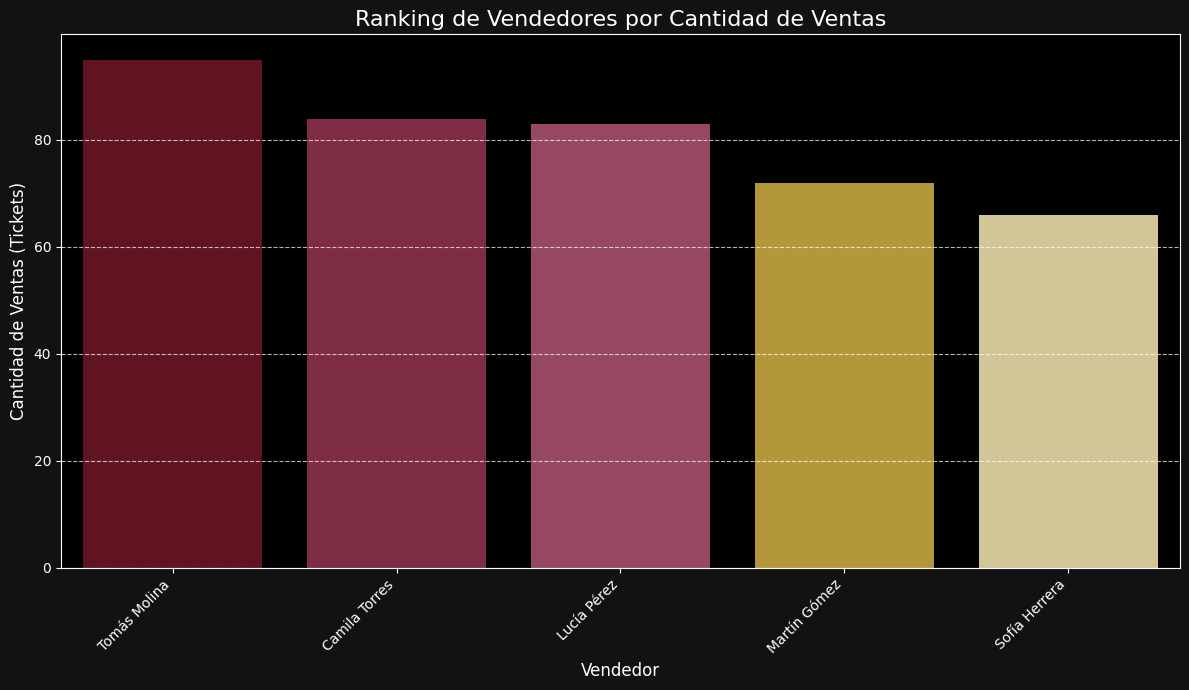

In [ ]:
ventas_por_vendedor_count = df['vendedor'].value_counts().reset_index()
ventas_por_vendedor_count.columns = ['vendedor', 'cantidad_ventas']

plt.figure(figsize=(12, 7), facecolor='#121212')
sns.barplot(x='vendedor', y='cantidad_ventas', data=ventas_por_vendedor_count, hue='vendedor', palette=paleta, legend=False)
plt.title('Ranking de Vendedores por Cantidad de Ventas', fontsize=16)
plt.xlabel('Vendedor', fontsize=12)
plt.ylabel('Cantidad de Ventas (Tickets)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
df['total_venta'] = pd.to_numeric(df['total_venta'], errors='coerce').fillna(0)
ventas_provincia = df.groupby("provincia")["total_venta"].sum().reset_index()

# Paleta de colores
paleta = [
    "#6D071A",
    "#8B1E3F",
    "#A23B5A",
    "#C9A227",
    "#DCCB8F"
]

fig = px.pie(
    ventas_provincia,
    values="total_venta",
    names="provincia",
    title="Distribución de Ventas por Provincia",
    color_discrete_sequence=paleta
)
fig.update_traces(textinfo="value", textposition="outside", hovertemplate="<b>Provincia:</b> %{label}<br><b>Total Ventas:</b> %{value:,.0f}<br><b>Porcentaje:</b> %{percent}<extra></extra>")
fig.show()

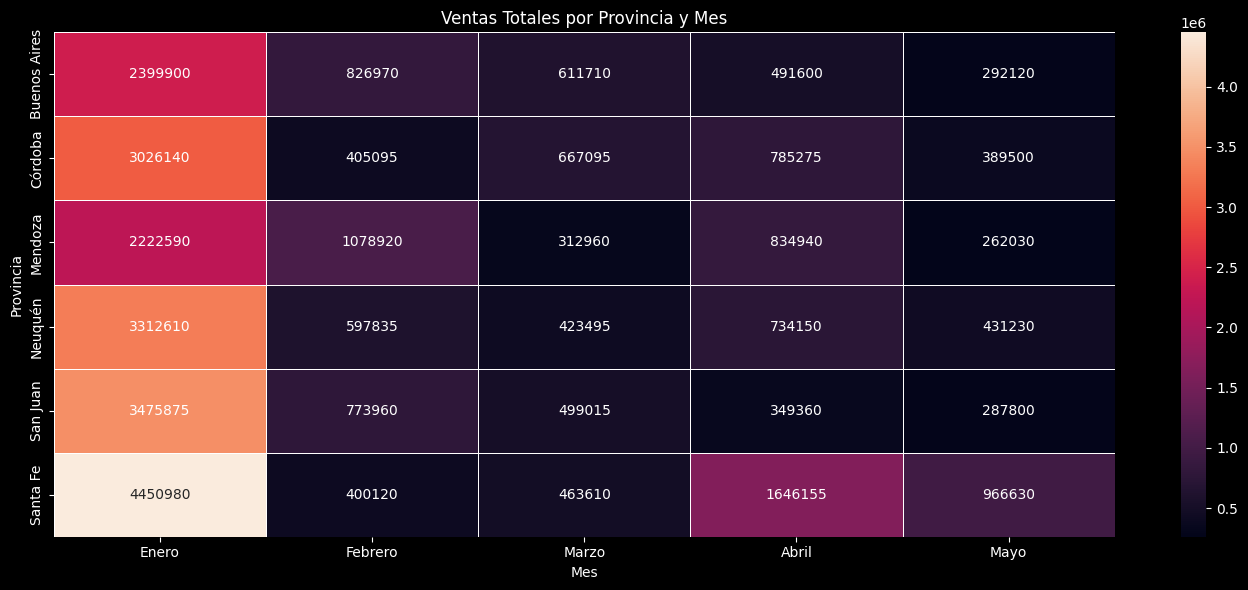

In [ ]:
# Crear número de mes
df["mes_num"] = df["fecha_venta"].dt.month

# Crear nombre del mes en español
meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
}

df["mes"] = df["mes_num"].map(meses)

# Crear tabla dinámica
tabla_heatmap = pd.pivot_table(
    df,
    values="total_venta",
    index="provincia",
    columns="mes",
    aggfunc="sum",
    fill_value=0
)

# Ordenar meses
orden_meses = [
    "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio",
    "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

# Mostrar solo los meses presentes
orden_existentes = [
    mes for mes in orden_meses
    if mes in tabla_heatmap.columns
]

tabla_heatmap = tabla_heatmap[orden_existentes]

# Crear gráfico
plt.figure(figsize=(14, 6))

sns.heatmap(
    tabla_heatmap,
    annot=True,
    fmt=".0f",
    cmap="rocket",
    linewidths=0.5
)

plt.title("Ventas Totales por Provincia y Mes")
plt.xlabel("Mes")
plt.ylabel("Provincia")

plt.tight_layout()
plt.show()

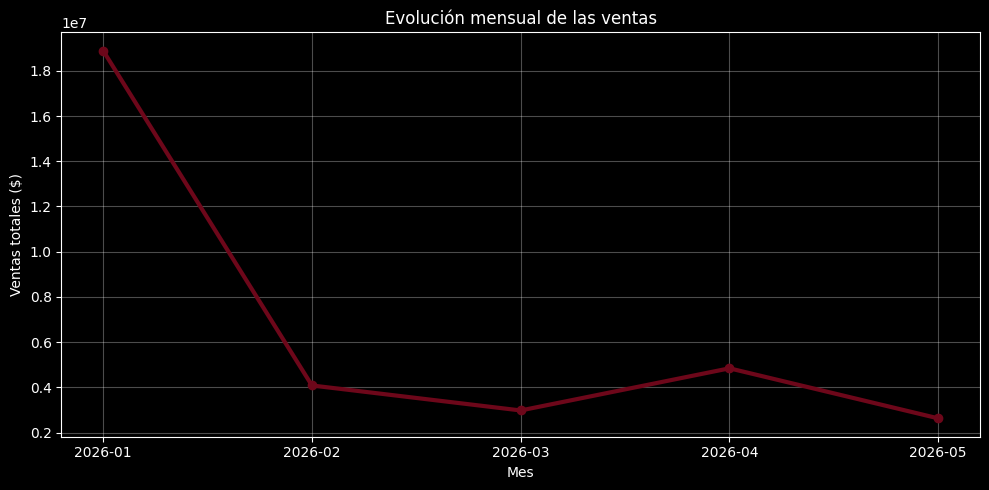

In [ ]:
ventas_mes = df.groupby(
    df["fecha_venta"].dt.to_period("M")
)["total_venta"].sum()

ventas_mes.index = ventas_mes.index.astype(str)

plt.figure(figsize=(10,5))

plt.plot(
    ventas_mes.index,
    ventas_mes.values,
    marker="o",
    linewidth=3,
    color="#6D071A"
)

plt.title("Evolución mensual de las ventas")
plt.xlabel("Mes")
plt.ylabel("Ventas totales ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

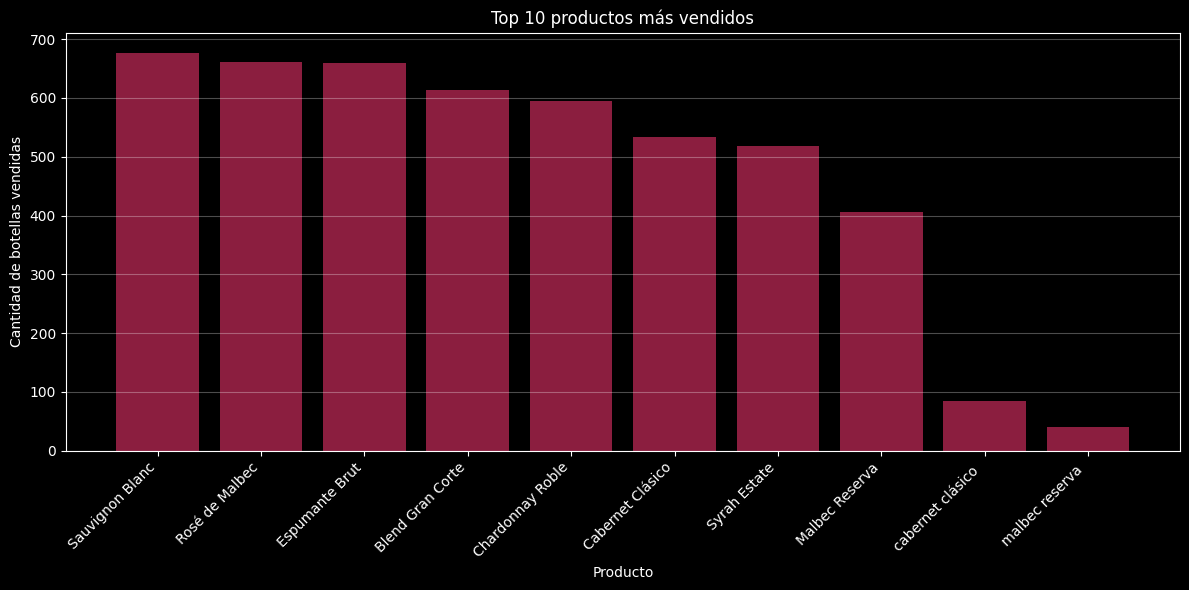

In [ ]:
top_productos = df.groupby("producto")["cantidad_botellas"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

plt.bar(
    top_productos.index,
    top_productos.values,
    color="#8B1E3F"
)

plt.title("Top 10 productos más vendidos")
plt.xlabel("Producto")
plt.ylabel("Cantidad de botellas vendidas")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

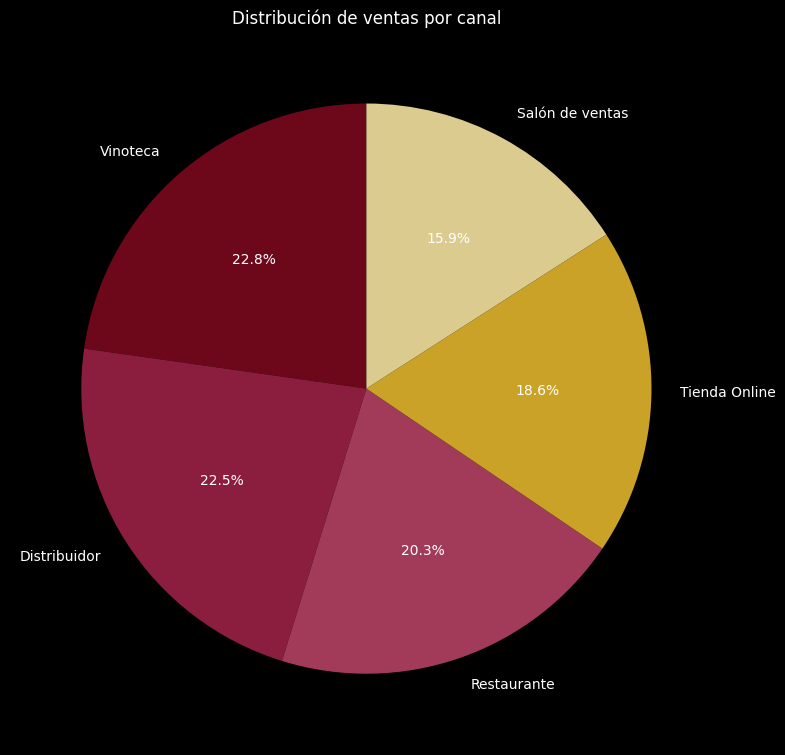

In [ ]:
ventas_canal = df.groupby("canal_venta")["total_venta"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,8))

plt.pie(
    ventas_canal,
    labels=ventas_canal.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=paleta
)

plt.title("Distribución de ventas por canal")
plt.tight_layout()
plt.show()

In [ ]:
!pip install dash -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 66.9 MB/s eta 0:00:00


In [ ]:
from dash import Dash, html, dcc
import plotly.express as px

app = Dash(__name__)

# Gráfico interactivo Plotly
ventas_mes = df.groupby("mes")["total_venta"].sum().reset_index()

fig_ventas = px.line(
    ventas_mes,
    x="mes",
    y="total_venta",
    markers=True,
    title="Evolución mensual de ventas"
)

app.layout = html.Div([
    html.H1("Dashboard de Ventas - Bodega"),

    html.Div([
        html.H3(f"Ventas totales: ${df['total_venta'].sum():,.0f}"),
        html.H3(f"Botellas vendidas: {df['cantidad_botellas'].sum():,.0f}"),
        html.H3(f"Ticket promedio: ${df['total_venta'].mean():,.0f}")
    ]),

    dcc.Graph(figure=fig_ventas)
])

app.run(debug=True)

Dash is running on http://127.0.0.1:8050/



INFO:dash.dash:Dash is running on http://127.0.0.1:8050/



 * Serving Flask app '__main__'
 * Debug mode: on
